<a href="https://colab.research.google.com/github/ggalarza1/BTC_accounting/blob/main/Bitcoin_ledger_bank_statement_generator.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### Bitcoin Ledger Bank Statement Generator
This notebook fetches public ledger data for a specified Bitcoin address and formats it into a standard bank statement.

In [ ]:
import requests
import pandas as pd
from datetime import datetime, timezone

def get_bitcoin_statement_enhanced(btc_address):
    url = f"https://blockchain.info/rawaddr/{btc_address}"
    response = requests.get(url)

    if response.status_code != 200:
        raise ValueError("Could not retrieve data. Please check the Bitcoin address.")

    data = response.json()
    txs = data.get("txs", [])
    final_balance = data.get("final_balance", 0) / 1e8

    statement_records = []

    # Process transactions in chronological order to calculate the shifting principal balance accurately
    sorted_txs = sorted(txs, key=lambda x: x.get("time", 0))
    running_balance = 0.0

    for tx in sorted_txs:
        tx_hash = tx.get("hash")
        timestamp = tx.get("time")
        date_dt = datetime.fromtimestamp(timestamp, timezone.utc)
        date_str = date_dt.strftime('%Y-%m-%d %H:%M:%S')

        # Find the source address (from inputs)
        inputs_list = tx.get("inputs", [])
        source_addresses = [inp.get("prev_out", {}).get("addr", "Unknown") for inp in inputs_list if inp.get("prev_out", {}).get("addr") is not None]
        source_address_str = ", ".join(set(source_addresses)) if source_addresses else "Unknown/Coinbase"

        inputs_sum = sum(inp.get("prev_out", {}).get("value", 0) for inp in inputs_list if inp.get("prev_out", {}).get("addr") == btc_address)
        outputs_sum = sum(out.get("value", 0) for out in tx.get("out", []) if out.get("addr") == btc_address)

        sent = inputs_sum / 1e8
        received = outputs_sum / 1e8
        net_flow = received - sent
        tx_type = "DEPOSIT" if net_flow > 0 else "WITHDRAWAL"

        running_balance += net_flow

        statement_records.append({
            "Date (UTC)": date_dt,
            "From Address": source_address_str,
            "Transaction Hash": f"{tx_hash[:8]}...{tx_hash[-8:]}",
            "Type": tx_type,
            "Amount (BTC)": abs(net_flow),
            "Account Principal (BTC)": running_balance
        })

    df = pd.DataFrame(statement_records)
    return df, final_balance

# Retrieve and display enhanced dataset
try:
    df_statement, final_balance = get_bitcoin_statement_enhanced(example_address)
    print("===========================================================")
    print(f"   BITCOIN LEDGER STATEMENT FOR ADDRESS: {example_address}")
    print(f"   TOTAL ACCOUNT BALANCE: {final_balance:.8f} BTC")
    print("===========================================================\n")
except Exception as e:
    print(f"Error fetching live ledger data: {e}")

   BITCOIN LEDGER STATEMENT FOR ADDRESS: 1A1zP1eP5QGefi2DMPTfTL5SLmv7DivfNa
   TOTAL ACCOUNT BALANCE: 107.67640420 BTC



### Separate Transactions by Month
Below, we group the retrieved ledger transactions by Year-Month and display the statement partitioned for each monthly period.

In [9]:
# Ensure we have full transaction hashes mapped in our notebook view
if 'df_statement' in locals() and 'raw_hashes' in locals():
    df_display['Transaction Hash'] = df_display['Transaction Hash'].apply(lambda h: raw_hashes.get(h, h))

# Keep all columns to display correctly
columns_to_keep = ['Date (UTC)', 'From Address', 'Transaction Hash', 'Type', 'Amount (BTC)', 'Account Principal (BTC)', 'Month Name']
df_display = df_display[columns_to_keep]

# Display individual bank-style statements grouped by month name
for month_name, group in df_display.groupby('Month Name', sort=False):
    # Calculate monthly subtotals and counts
    deposit_group = group[group['Type'] == 'DEPOSIT']
    withdrawal_group = group[group['Type'] == 'WITHDRAWAL']

    monthly_deposits = deposit_group['Amount (BTC)'].sum()
    monthly_withdrawals = withdrawal_group['Amount (BTC)'].sum()

    count_deposits = len(deposit_group)
    count_withdrawals = len(withdrawal_group)

    # Render the structured bank statement header
    print("\n" + "="*70)
    print(f"                   BITCOIN LEDGER BANK STATEMENT")
    print(f" STATEMENT PERIOD: {month_name.upper()}")
    print(f" ACCOUNT HOLDER  : {example_address}")
    print(f" CURRENT BALANCE : {final_balance:.8f} BTC")
    print("-"*70)
    print(f" PERIOD SUB-TOTALS:")
    print(f"   TOTAL DEPOSITS:    +{monthly_deposits:.8f} BTC ({count_deposits} transactions)")
    print(f"   TOTAL WITHDRAWALS: -{monthly_withdrawals:.8f} BTC ({count_withdrawals} transactions)")
    print("="*70 + "\n")

    # 1. Deposits Section (Removing Type)
    print("\033[1mDeposits\033[0m")
    if not deposit_group.empty:
        formatted_deposits = deposit_group.copy()
        formatted_deposits['Date (UTC)'] = formatted_deposits['Date (UTC)'].dt.strftime('%Y-%m-%d %H:%M:%S')
        display(formatted_deposits.drop(columns=['Type', 'Month Name']))
    else:
        print("No deposits recorded during this statement period.\n")

    print("\n" + "-"*70 + "\n")

    # 2. Expenses Section (Removing Type)
    print("\033[1mExpenses\033[0m")
    if not withdrawal_group.empty:
        formatted_expenses = withdrawal_group.copy()
        formatted_expenses['Date (UTC)'] = formatted_expenses['Date (UTC)'].dt.strftime('%Y-%m-%d %H:%M:%S')
        display(formatted_expenses.drop(columns=['Type', 'Month Name']))
    else:
        print("No expenses recorded during this statement period.\n")


                   BITCOIN LEDGER BANK STATEMENT
 STATEMENT PERIOD: OCTOBER 2026
 ACCOUNT HOLDER  : 1A1zP1eP5QGefi2DMPTfTL5SLmv7DivfNa
 CURRENT BALANCE : 107.69177140 BTC
----------------------------------------------------------------------
 PERIOD SUB-TOTALS:
   TOTAL DEPOSITS:    +0.01643474 BTC (100 transactions)
   TOTAL WITHDRAWALS: -0.00000000 BTC (0 transactions)

Deposits


,Date (UTC),From Address,Transaction Hash,Amount (BTC),Account Principal (BTC)
99,2026-10-20 17:21:47,1BxhqQFFp925uMXgEtgTBBdCZxBwVFAw13,126f07c71e3037026000751a09d0528f104c5c33305fac...,0.000005,0.016435
98,2026-10-20 16:46:11,bc1pge0tgdp5c9wmjlq3ge694fne4jterr773u9amv0m4j...,a12e6bbbaf86f7f06293c754e4ed8c39f490678a989d20...,0.000104,0.016429
97,2026-10-20 15:45:59,bc1pge0tgdp5c9wmjlq3ge694fne4jterr773u9amv0m4j...,9753fe91cfe4d927ee39583f05a9fc1307284787ecdf8f...,0.000107,0.016325
96,2026-10-20 14:15:00,bc1qhk7w6ejeemwjcasdul82y985v2wc6vf4sr2r6v,e0415fcda0ff8c25dc75f049edfeb6c9fdbcb1da152e76...,0.000603,0.016218
95,2026-10-20 13:46:15,3B4eLPh3XuhW9HgvBqEmjG8TTy8ZnBG9jB,51bf344590c13c2f5128d17708d5c6d949ec0b05e3966e...,0.000005,0.015615
...,...,...,...,...,...
4,2026-10-17 13:43:11,bc1pge0tgdp5c9wmjlq3ge694fne4jterr773u9amv0m4j...,5842ba6f7212d53d98db5dfa1aa04ef3c00e80d714bb62...,0.000104,0.000345
3,2026-10-17 08:30:11,bc1pq0kaymsw47hctta3uh74k36m8qjm8xpzyvtqwfc7q2...,890f38447ef803c4220e925fbf97728a3c49cc10a4d6db...,0.000005,0.000241
2,2026-10-17 05:32:28,bc1pge0tgdp5c9wmjlq3ge694fne4jterr773u9amv0m4j...,81c4db75ed772f8a2fb5a3d08af93cc281bf26588e0105...,0.000120,0.000236
1,2026-10-17 05:22:42,bc1q9qkjc8x853msxzsykp5qc5hjc0uav8ak4wwj5q,cfc712e7d7c0ccd63c6fda58414c9dbf141d628a65ab6b...,0.000005,0.000116



----------------------------------------------------------------------

Expenses
No expenses recorded during this statement period.



### Calculate and Visualize Rolling Balance Over Time
To find the balance over time, we assign a positive sign to deposits and a negative sign to withdrawals. Then, we sort chronologically and compute the cumulative sum of these transaction amounts.

Transactions with Rolling Balance:


,Date (UTC),Type,Amount (BTC),Net Flow (BTC),Rolling Balance (BTC)
90,2026-10-17 13:43:10+00:00,DEPOSIT,0.000104,0.000104,0.083551
91,2026-10-17 14:23:25+00:00,DEPOSIT,0.000005,0.000005,0.083556
92,2026-10-17 18:47:46+00:00,DEPOSIT,0.000100,0.000100,0.083657
93,2026-10-17 19:25:09+00:00,DEPOSIT,0.000142,0.000142,0.083798
94,2026-10-17 19:30:16+00:00,DEPOSIT,0.000095,0.000095,0.083893
95,2026-10-17 19:46:27+00:00,DEPOSIT,0.000118,0.000118,0.084012
96,2026-10-17 20:00:03+00:00,DEPOSIT,0.000100,0.000100,0.084111
97,2026-10-17 20:05:43+00:00,DEPOSIT,0.000005,0.000005,0.084117
98,2026-10-17 20:37:54+00:00,DEPOSIT,0.000008,0.000008,0.084125
99,2026-10-18 02:35:01+00:00,DEPOSIT,0.000148,0.000148,0.084273


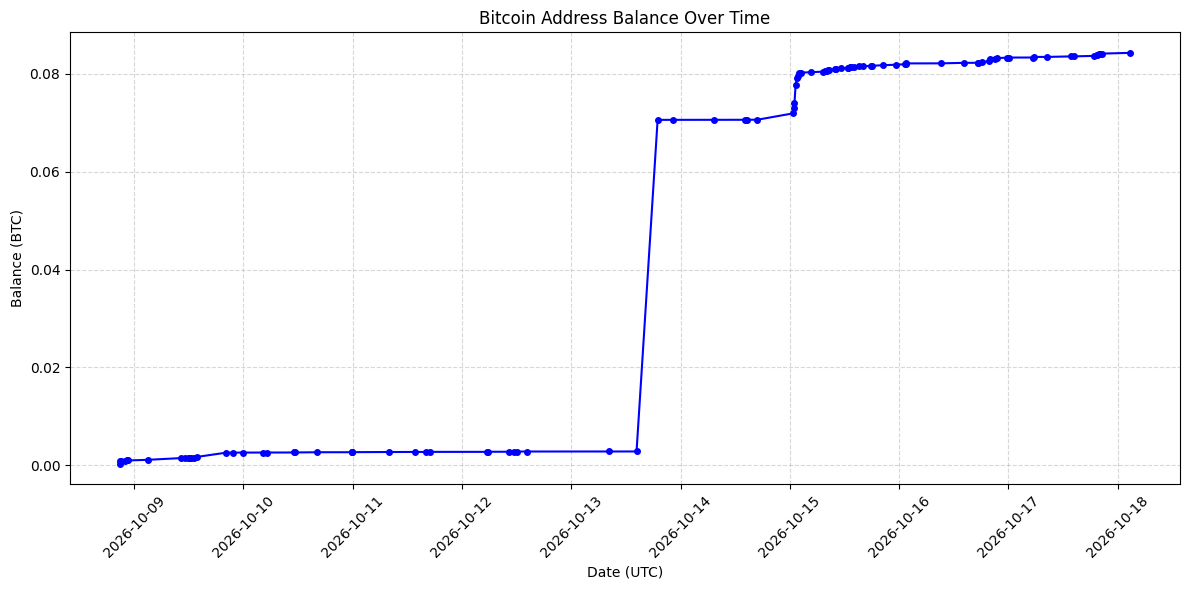

In [ ]:
import matplotlib.pyplot as plt

# Create a copy of the dataframe to calculate the balance securely
df_balance = df_statement.copy()

# Sort chronologically (oldest transactions first) to calculate the rolling balance correctly
df_balance['Date (UTC)'] = pd.to_datetime(df_balance['Date (UTC)'])
df_balance = df_balance.sort_values(by='Date (UTC)').reset_index(drop=True)

# Map transaction types to positive/negative values
df_balance['Net Flow (BTC)'] = df_balance.apply(
    lambda row: row['Amount (BTC)'] if row['Type'] == 'DEPOSIT' else -row['Amount (BTC)'],
    axis=1
)

# Calculate the cumulative (rolling) balance
df_balance['Rolling Balance (BTC)'] = df_balance['Net Flow (BTC)'].cumsum()

# Display the top rows of the updated dataframe
print("Transactions with Rolling Balance:")
display(df_balance[['Date (UTC)', 'Type', 'Amount (BTC)', 'Net Flow (BTC)', 'Rolling Balance (BTC)']].tail(10))

# Plot the rolling balance over time
plt.figure(figsize=(12, 6))
plt.plot(df_balance['Date (UTC)'], df_balance['Rolling Balance (BTC)'], marker='o', linestyle='-', color='b', markersize=4)
plt.title('Bitcoin Address Balance Over Time')
plt.xlabel('Date (UTC)')
plt.ylabel('Balance (BTC)')
plt.grid(True, linestyle='--', alpha=0.5)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Daily Balance Growth Percentage
Next, we'll aggregate the rolling balance to find the ending balance for each day and calculate the day-over-day percentage growth.

In [ ]:
# Group by Date (ignoring time) to find the daily ending balance
df_daily = df_balance.groupby(df_balance['Date (UTC)'].dt.date).agg(
    Daily_Net_Flow=('Net Flow (BTC)', 'sum'),
    Ending_Balance=('Rolling Balance (BTC)', 'last')
).reset_index()

# Calculate day-over-day percentage growth of the total balance
df_daily['Balance Growth (%)'] = df_daily['Ending_Balance'].pct_change() * 100

print("Daily Balance Growth Analysis:")
display(df_daily)

Daily Balance Growth Analysis:


,Date (UTC),Daily_Net_Flow,Ending_Balance,Balance Growth (%)
0,2026-10-08,0.001001,0.001001,NaN
1,2026-10-09,0.001599,0.002600,159.695157
2,2026-10-10,0.000094,0.002694,3.607322
3,2026-10-11,0.000059,0.002753,2.195428
4,2026-10-12,0.000074,0.002827,2.692777
5,2026-10-13,0.067762,0.070589,2396.903132
6,2026-10-14,0.000028,0.070616,0.039029
7,2026-10-15,0.011235,0.081851,15.909398
8,2026-10-16,0.001455,0.083306,1.777770
9,2026-10-17,0.000819,0.084125,0.983087


### Bar chart of the Daily Net Flor of BTC

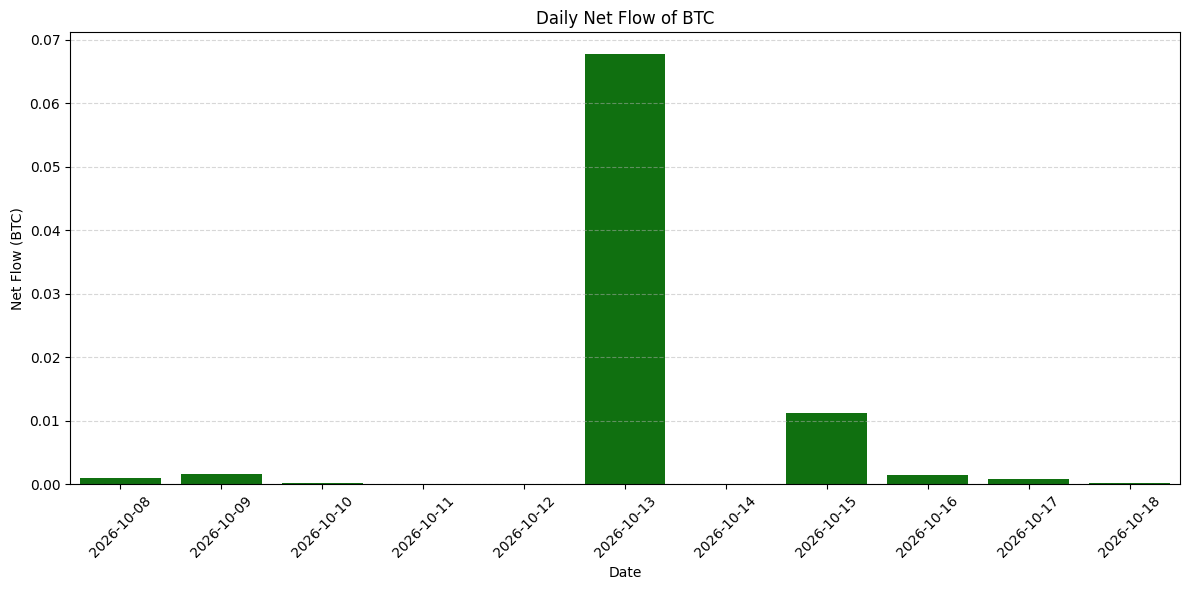

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Create a bar chart for daily net flow of BTC
plt.figure(figsize=(12, 6))
colors = ['red' if x < 0 else 'green' for x in df_daily['Daily_Net_Flow']]
sns.barplot(x='Date (UTC)', y='Daily_Net_Flow', data=df_daily, palette=colors, hue='Date (UTC)', legend=False)

plt.title('Daily Net Flow of BTC')
plt.xlabel('Date')
plt.ylabel('Net Flow (BTC)')
plt.grid(True, linestyle='--', alpha=0.5, axis='y')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Bitcoin Statement exporting it to excel

In [10]:
import os
import pandas as pd
from google.colab import files
import openpyxl
from openpyxl.utils.dataframe import dataframe_to_rows
from openpyxl.drawing.image import Image as OpenpyxlImage
from PIL import Image as PILImage
import requests
from datetime import datetime, timezone
from openpyxl.styles import Font

# Fallback definition in case preceding cells were not executed
try:
    df_display
    df_balance
    df_daily
    example_address
    final_balance
except NameError:
    print("Dependencies not found in memory. Re-fetching data...")

    def get_bitcoin_statement_enhanced(btc_address):
        url = f"https://blockchain.info/rawaddr/{btc_address}"
        response = requests.get(url)
        if response.status_code != 200:
            raise ValueError("Could not retrieve data. Please check the Bitcoin address.")
        data = response.json()
        txs = data.get("txs", [])
        final_bal = data.get("final_balance", 0) / 1e8
        statement_records = []
        sorted_txs = sorted(txs, key=lambda x: x.get("time", 0))
        running_balance = 0.0
        for tx in sorted_txs:
            tx_hash = tx.get("hash")
            timestamp = tx.get("time")
            date_dt = datetime.fromtimestamp(timestamp, timezone.utc)
            inputs_list = tx.get("inputs", [])
            source_addresses = [inp.get("prev_out", {}).get("addr", "Unknown") for inp in inputs_list if inp.get("prev_out", {}).get("addr") is not None]
            source_address_str = ", ".join(set(source_addresses)) if source_addresses else "Unknown/Coinbase"
            inputs_sum = sum(inp.get("prev_out", {}).get("value", 0) for inp in inputs_list if inp.get("prev_out", {}).get("addr") == btc_address)
            outputs_sum = sum(out.get("value", 0) for out in tx.get("out", []) if out.get("addr") == btc_address)
            sent = inputs_sum / 1e8
            received = outputs_sum / 1e8
            net_flow = received - sent
            tx_type = "DEPOSIT" if net_flow > 0 else "WITHDRAWAL"
            running_balance += net_flow
            statement_records.append({
                "Date (UTC)": date_dt,
                "From Address": source_address_str,
                "Transaction Hash": tx_hash,  # Keep full hash instead of truncating
                "Type": tx_type,
                "Amount (BTC)": abs(net_flow),
                "Account Principal (BTC)": running_balance
            })
        df = pd.DataFrame(statement_records)
        return df, final_bal

    example_address = "1A1zP1eP5QGefi2DMPTfTL5SLmv7DivfNa"
    df_statement, final_balance = get_bitcoin_statement_enhanced(example_address)

    # Sort transactions reverse-chronologically
    df_display = df_statement.sort_values(by='Date (UTC)', ascending=False).copy()
    df_display['Month Name'] = df_display['Date (UTC)'].dt.strftime('%B %Y')
    columns_to_keep = ['Date (UTC)', 'From Address', 'Transaction Hash', 'Type', 'Amount (BTC)', 'Account Principal (BTC)', 'Month Name']
    df_display = df_display[columns_to_keep]

    # Calculate rolling balance
    df_balance = df_statement.copy()
    df_balance['Date (UTC)'] = pd.to_datetime(df_balance['Date (UTC)'])
    df_balance = df_balance.sort_values(by='Date (UTC)').reset_index(drop=True)
    df_balance['Net Flow (BTC)'] = df_balance.apply(
        lambda row: row['Amount (BTC)'] if row['Type'] == 'DEPOSIT' else -row['Amount (BTC)'],
        axis=1
    )
    df_balance['Rolling Balance (BTC)'] = df_balance['Net Flow (BTC)'].cumsum()

    # Calculate daily statistics
    df_daily = df_balance.groupby(df_balance['Date (UTC)'].dt.date).agg(
        Daily_Net_Flow=('Net Flow (BTC)', 'sum'),
        Ending_Balance=('Rolling Balance (BTC)', 'last')
    ).reset_index()
    df_daily['Balance Growth (%)'] = df_daily['Ending_Balance'].pct_change() * 100

# Ensure we have full transaction hashes
if 'df_statement' in locals():
    # Re-map full transaction hashes from raw data to guarantee full coverage
    raw_hashes = {f"{tx['hash'][:8]}...{tx['hash'][-8:]}": tx['hash'] for tx in sorted(requests.get(f"https://blockchain.info/rawaddr/{example_address}").json().get("txs", []), key=lambda x: x.get("time", 0))}
    df_display['Transaction Hash'] = df_display['Transaction Hash'].apply(lambda h: raw_hashes.get(h, h))

columns_to_keep_final = ['Date (UTC)', 'From Address', 'Transaction Hash', 'Type', 'Amount (BTC)', 'Account Principal (BTC)', 'Month Name']
df_display_excel = df_display[columns_to_keep_final].copy()

# Prepare copies of DataFrames without timezone info for safe Excel writing
if pd.api.types.is_datetime64_any_dtype(df_display_excel['Date (UTC)']):
    df_display_excel['Date (UTC)'] = df_display_excel['Date (UTC)'].dt.tz_localize(None)

df_balance_excel = df_balance.copy()
if pd.api.types.is_datetime64_any_dtype(df_balance_excel['Date (UTC)']):
    df_balance_excel['Date (UTC)'] = df_balance_excel['Date (UTC)'].dt.tz_localize(None)

# Define the output file name
excel_file = 'bitcoin_bank_statement_enhanced.xlsx'
logo_file = '/content/images.png'

has_image = False
# Check and prepare the logo image provided by the user
if os.path.exists(logo_file):
    try:
        img = PILImage.open(logo_file)
        img.thumbnail((120, 120))
        temp_logo_path = 'temp_bank_logo.png'
        img.save(temp_logo_path)
        logo_file = temp_logo_path
        has_image = True
    except Exception as e:
        print(f"Could not load or resize user image: {e}. Proceeding without logo.")
else:
    print(f"Specified image file not found at {logo_file}. Proceeding without logo.")

# First, write the standard tables using standard pandas integration
with pd.ExcelWriter(excel_file, engine='openpyxl') as writer:
    df_balance_excel[['Date (UTC)', 'Type', 'Amount (BTC)', 'Net Flow (BTC)', 'Rolling Balance (BTC)']].to_excel(writer, sheet_name='Rolling Balance', index=False)
    df_daily.to_excel(writer, sheet_name='Daily Summary & Growth', index=False)

# Re-open the saved workbook to add the styled transaction statement with custom headers and logo
wb = openpyxl.load_workbook(excel_file)

# Create our custom statement worksheet as the first sheet
ws_stmt = wb.create_sheet(title='Transaction Statement', index=0)

# Insert Logo Image at the top left (A1) if successfully created
if has_image:
    img_to_insert = OpenpyxlImage(logo_file)
    ws_stmt.add_image(img_to_insert, 'A1')

# Font styling
bold_font = Font(name='Calibri', size=11, bold=True)

# Write monthly statements sequentially
row_idx = 1
for month_name, group in df_display_excel.groupby('Month Name', sort=False):
    # Calculate monthly subtotals and counts
    deposit_group = group[group['Type'] == 'DEPOSIT']
    withdrawal_group = group[group['Type'] == 'WITHDRAWAL']

    monthly_deposits = deposit_group['Amount (BTC)'].sum()
    monthly_withdrawals = withdrawal_group['Amount (BTC)'].sum()

    count_deposits = len(deposit_group)
    count_withdrawals = len(withdrawal_group)

    # Place the bank statement headers and subtotals starting in column B (B1, B2, etc.) next to the logo
    header_col = 2
    ws_stmt.cell(row=row_idx, column=header_col, value="BITCOIN LEDGER BANK STATEMENT")
    row_idx += 1
    ws_stmt.cell(row=row_idx, column=header_col, value=f"STATEMENT PERIOD: {month_name.upper()}")
    row_idx += 1
    ws_stmt.cell(row=row_idx, column=header_col, value=f"ACCOUNT HOLDER  : {example_address}")
    row_idx += 1
    ws_stmt.cell(row=row_idx, column=header_col, value=f"CURRENT BALANCE : {final_balance:.8f} BTC")
    row_idx += 1
    ws_stmt.cell(row=row_idx, column=header_col, value="-" * 70)
    row_idx += 1
    ws_stmt.cell(row=row_idx, column=header_col, value="PERIOD SUB-TOTALS:")
    row_idx += 1
    ws_stmt.cell(row=row_idx, column=header_col, value=f"  TOTAL DEPOSITS:    +{monthly_deposits:.8f} BTC ({count_deposits} transactions)")
    row_idx += 1
    ws_stmt.cell(row=row_idx, column=header_col, value=f"  TOTAL WITHDRAWALS: -{monthly_withdrawals:.8f} BTC ({count_withdrawals} transactions)")
    row_idx += 1
    ws_stmt.cell(row=row_idx, column=header_col, value="=" * 70)

    # Push transaction list start row below the header blocks
    row_idx += 2

    # 1. Write Deposits Section (Drop 'Type' and 'Month Name' columns)
    dep_cell = ws_stmt.cell(row=row_idx, column=1, value="Deposits")
    dep_cell.font = bold_font
    row_idx += 1

    clean_deposits = deposit_group.drop(columns=['Type', 'Month Name'])
    # Write Deposits Header Row
    for col_idx, col_name in enumerate(clean_deposits.columns, 1):
        ws_stmt.cell(row=row_idx, column=col_idx, value=col_name)
    row_idx += 1

    # Write Deposits Data Rows
    for r in dataframe_to_rows(clean_deposits, index=False, header=False):
        for col_idx, value in enumerate(r, 1):
            if isinstance(value, pd.Timestamp):
                value = value.strftime('%Y-%m-%d %H:%M:%S')
            ws_stmt.cell(row=row_idx, column=col_idx, value=value)
        row_idx += 1

    row_idx += 2  # Spacing before next section

    # 2. Write Expenses Section (Drop 'Type' and 'Month Name' columns)
    exp_cell = ws_stmt.cell(row=row_idx, column=1, value="Expenses")
    exp_cell.font = bold_font
    row_idx += 1

    clean_expenses = withdrawal_group.drop(columns=['Type', 'Month Name'])
    # Write Expenses Header Row
    for col_idx, col_name in enumerate(clean_expenses.columns, 1):
        ws_stmt.cell(row=row_idx, column=col_idx, value=col_name)
    row_idx += 1

    # Write Expenses Data Rows
    for r in dataframe_to_rows(clean_expenses, index=False, header=False):
        for col_idx, value in enumerate(r, 1):
            if isinstance(value, pd.Timestamp):
                value = value.strftime('%Y-%m-%d %H:%M:%S')
            ws_stmt.cell(row=row_idx, column=col_idx, value=value)
        row_idx += 1

    row_idx += 3  # Add spacing between monthly sections

# Ensure the 'Transaction Statement' is set as the active tab
wb.active = 0
wb.save(excel_file)

print(f"Enhanced Excel workbook '{excel_file}' with custom Statement headers and logo successfully created!")

# Trigger browser download of the file
files.download(excel_file)

Enhanced Excel workbook 'bitcoin_bank_statement_enhanced.xlsx' with custom Statement headers and logo successfully created!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>